# Step 3d: sheet density against gate voltage, paper Fig. 4(b)
Region solutions Eqs. (9), (11)–(12), (14) joined by Eq. (15) (sign fixed), against the exact root-finding solution and the paper's points
[P, Eqs. (8)–(15), Fig. 4(b); corrections and fitted values labelled in gate.py].

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gate import n_exact, n_sub_V, n_mid_V, n_on_V, n_total, V_OFF

paper = np.loadtxt("paper_data/fig4b_markers.csv", delimiter=",", skiprows=3)   # [P] Fig. 4(b)

In [2]:
V = np.linspace(-6, 0, 601)                        # gate voltages, V
n_ex = np.array([n_exact(v)[0] for v in V])        # exact, by root finding
n_tot = n_total(V)                                 # compact model, Eq. (15)
ok = n_tot > 0                                     # Eq. (15) goes slightly negative deep below threshold
print(f"n_total stays positive above V_GS = {V[ok][0]:+.2f} V")

n_total stays positive above V_GS = -4.45 V


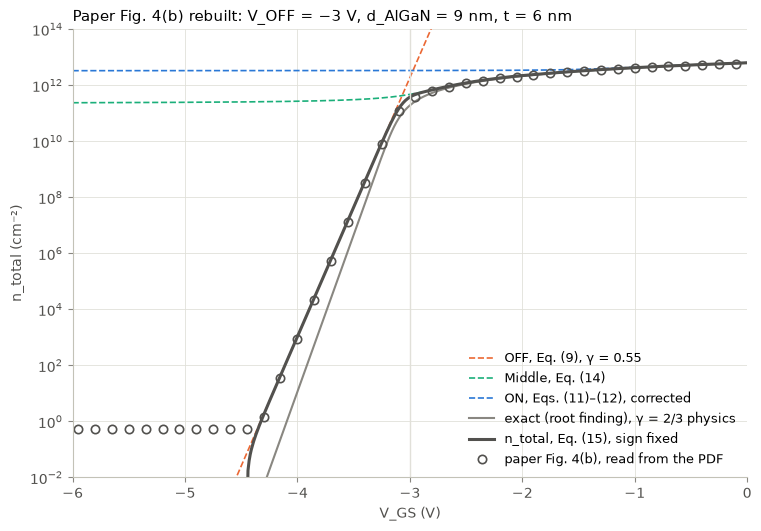

In [3]:
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
fig, ax = plt.subplots(figsize=(7.5, 5.2), constrained_layout=True)

# the three region formulas (dashed), each good only in its own range
ax.semilogy(V, n_sub_V(V), color=ORANGE, lw=1.2, ls="--", label="OFF, Eq. (9), γ = 0.55")
ax.semilogy(V, n_mid_V(V), color=AQUA, lw=1.2, ls="--", label="Middle, Eq. (14)")
ax.semilogy(V, n_on_V(V), color=BLUE, lw=1.2, ls="--", label="ON, Eqs. (11)–(12), corrected")

# the exact physics and the joined compact model
ax.semilogy(V, n_ex, color=MUTED, lw=1.5, label="exact (root finding), γ = 2/3 physics")
ax.semilogy(V[ok], n_tot[ok], color=INK, lw=2.2, label="n_total, Eq. (15), sign fixed")

# the paper's points
ax.semilogy(paper[:, 0], paper[:, 1], "o", mfc="none", mec=INK, ms=6, mew=1.2, label="paper Fig. 4(b), read from the PDF")

ax.axvline(V_OFF, color=GRID, lw=1)                # V_OFF = -3 V
ax.set_xlim(-6, 0); ax.set_ylim(1e-2, 1e14)
ax.set_xlabel("V_GS (V)"); ax.set_ylabel("n_total (cm⁻²)")
ax.set_title("Paper Fig. 4(b) rebuilt: V_OFF = −3 V, d_AlGaN = 9 nm, t = 6 nm", loc="left", fontsize=11)
ax.grid(True, color=GRID, lw=0.6); ax.legend(loc="lower right", fontsize=9)

fig.savefig("figures/step3d_fig4b.png", dpi=200)
plt.show()